# IMPORT LIBRARY

In [1]:
import os
import random
import datetime
import json
import pandas   as pd
import numpy    as np

from tqdm                               import tqdm
from preProcessingDataTEP               import PreProcessData
from utility.matpilotDraw               import MatPlot

with open('utility/modelConfig.json', 'r') as configFile:
    config = json.load(configFile)
myConfig   = config["tep"]

2025-04-27 12:44:55.814283: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-04-27 12:44:55.970518: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-04-27 12:44:56.743566: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/home/ducan/anaconda3/envs/tensorflow2.10.0Crusher/lib/
2025-04-27 12:44:56.743699: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer_plugin.so.7'; dlerro

# LOADING DATA

In [2]:
# This function is used to load and save data into H5 file
# preData     = PreProcessData(config=myConfig)
# outputDir   = os.path.expanduser(preData.config["dataDir"])    
# oriData     = preData.loadCSVDataFile(dir               = outputDir, 
#                                       removeHigherThr   = True, 
#                                       columnNames       = ["Stripper Level","Stripper Level","Stripper Level"],
#                                       thr               = ["down", "down", "up"]) 




# preData.save2H5Format(dir = outputDir, data = oriData)

In [2]:
plot               = MatPlot() 

# ----------------------    
# Reactor, Separator,Stripper
# ----------------------
np.random.seed(1)
random.seed(1)

preData     = PreProcessData(config=myConfig)
outputDir   = os.path.expanduser(preData.config["dataDir"])
rawData             = preData.loadDataFromH5Format(dir = outputDir, name="data/teps.h5", case="all", reduceSampleRate = False)

withRULData         = preData.addRULAndEnvironment(rawData)
cleanData           = preData.cleanData(   rawSignal           =   withRULData,
                                                columnName          =   preData.allWithoutLabel,
                                                getMovingAverage    =   False,
                                                flipToDown          =   True)
# ---------------------------
# For label, flip only
cleanData           = preData.cleanData(rawSignal              =   cleanData,
                                        columnName          =   preData.degraLiq,
                                        getMovingAverage    =   False,
                                        flipToDown          =   True)
# print(rawData[1])


Process:123946||2025-04-27 12:44:57,958-INFO [preProcessingDataTEP.py:loadDataFromH5Format():305]:Loading data from H5 files ...
Process:123946||2025-04-27 12:44:59,431-INFO [preProcessingDataTEP.py:loadDataFromH5Format():332]:Finish loading data from H5 files at case all...
Process:123946||2025-04-27 12:44:59,629-INFO [preProcessingDataTEP.py:addRULAndEnvironment():381]:Adding rul successfully...
Process:123946||2025-04-27 12:44:59,630-INFO [preProcessingDataTEP.py:cleanData():458]:Cleaning data ...
Process:123946||2025-04-27 12:44:59,630-INFO [preProcessingDataTEP.py:cleanData():478]:Flipping data at case 1
/home/ducan/Documents/2ndrealdatajournalchile/preProcessingDataTEP.py:479: FutureWarning: Not prepending group keys to the result index of transform-like apply. In the future, the group keys will be included in the index, regardless of whether the applied function returns a like-indexed object.
To preserve the previous behavior, use

	>>> .groupby(..., group_keys=False)

To adopt 

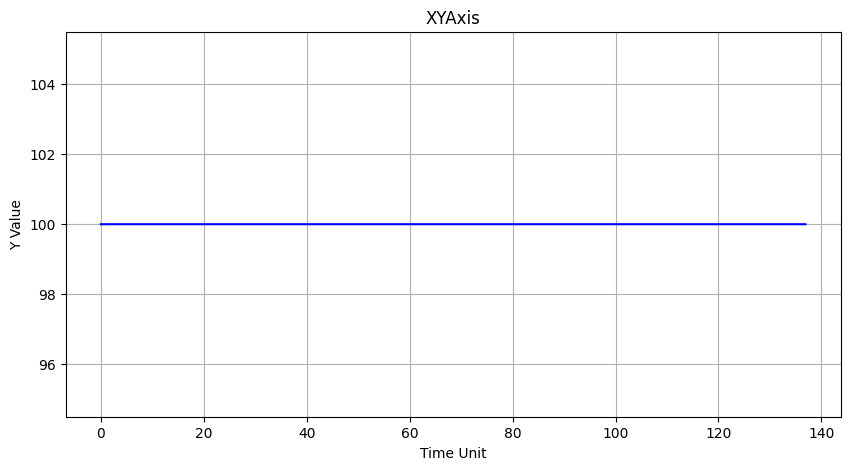

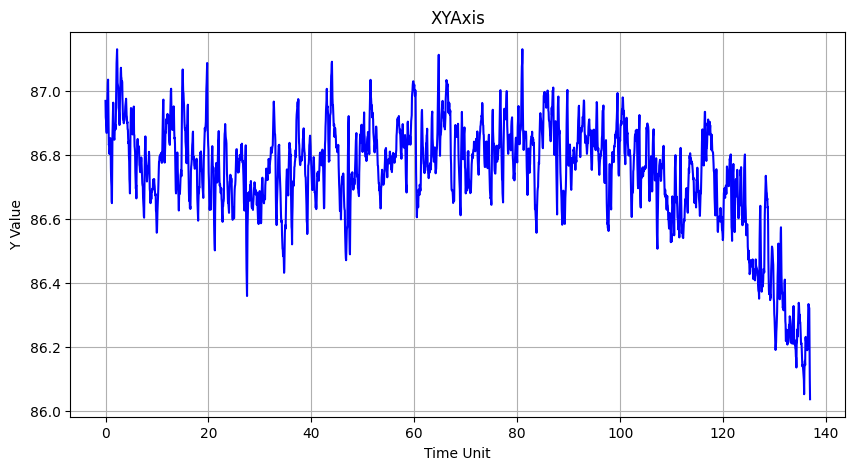

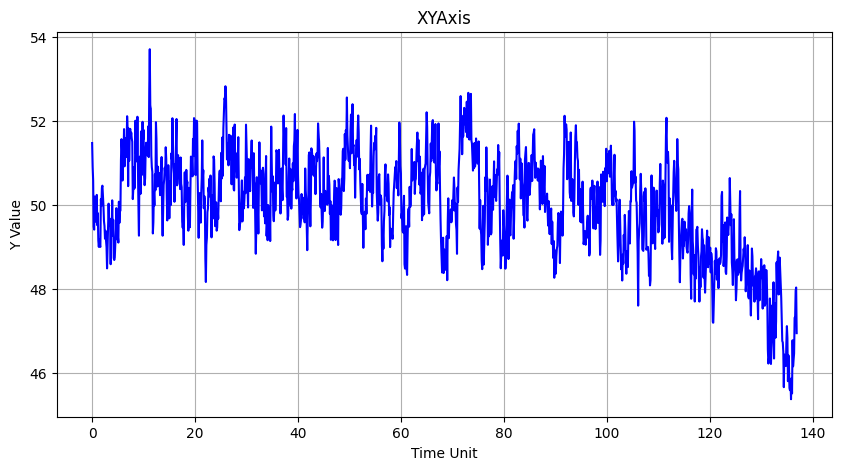

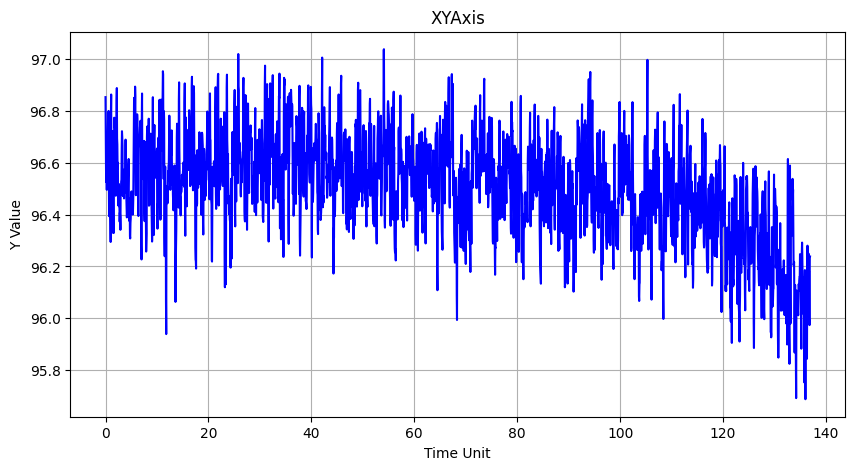

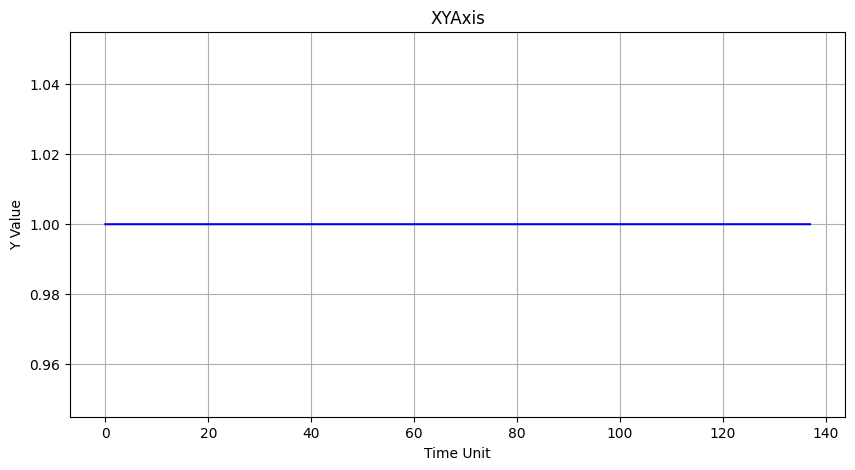

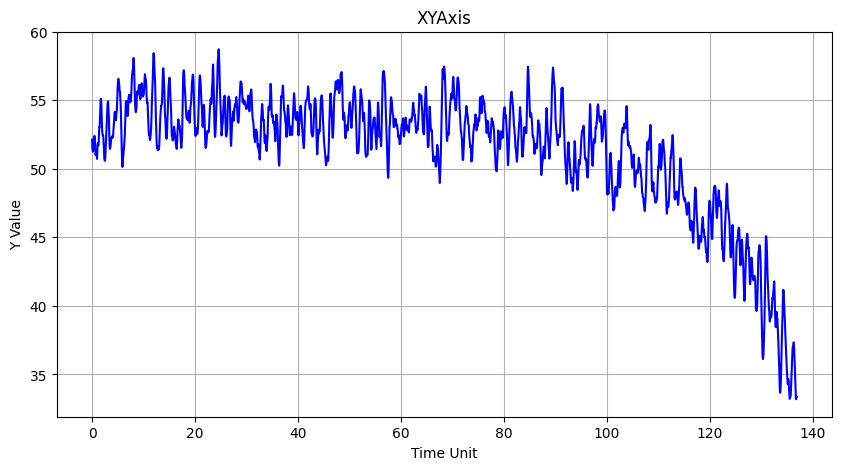

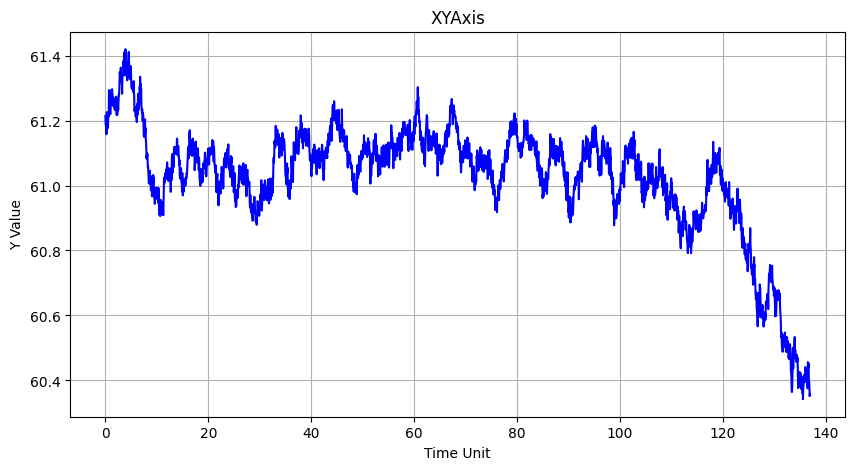

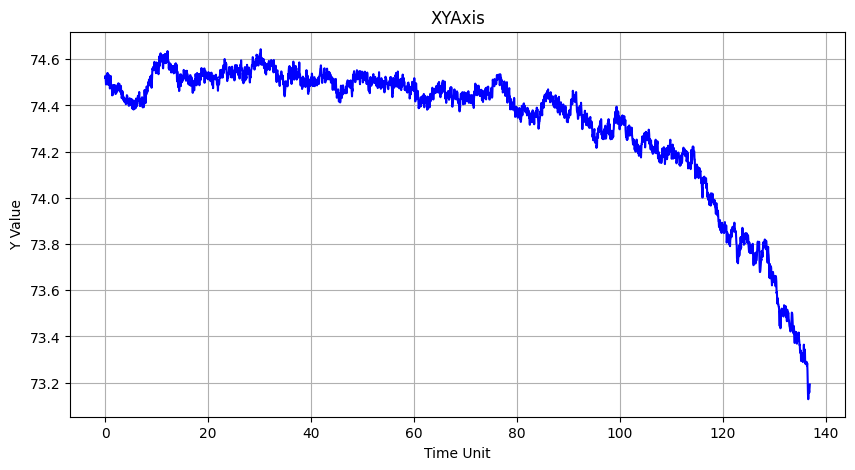

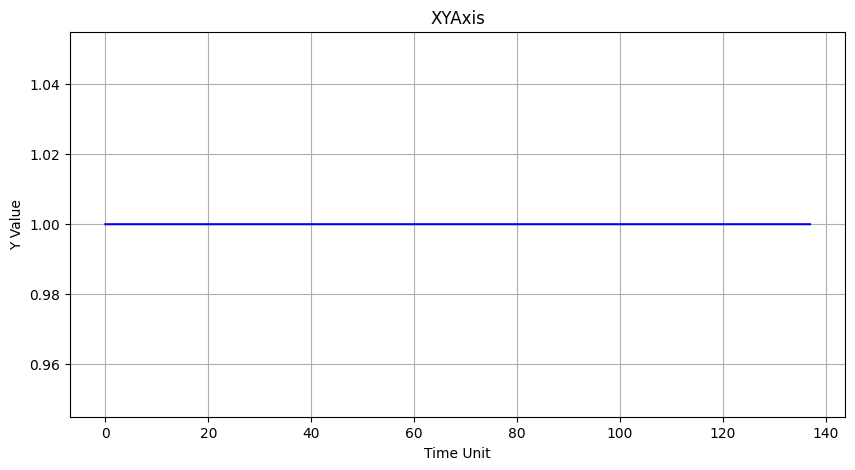

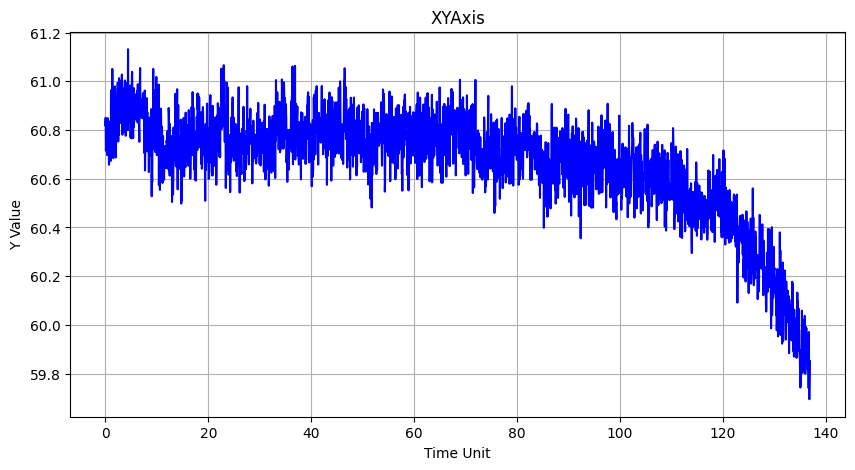

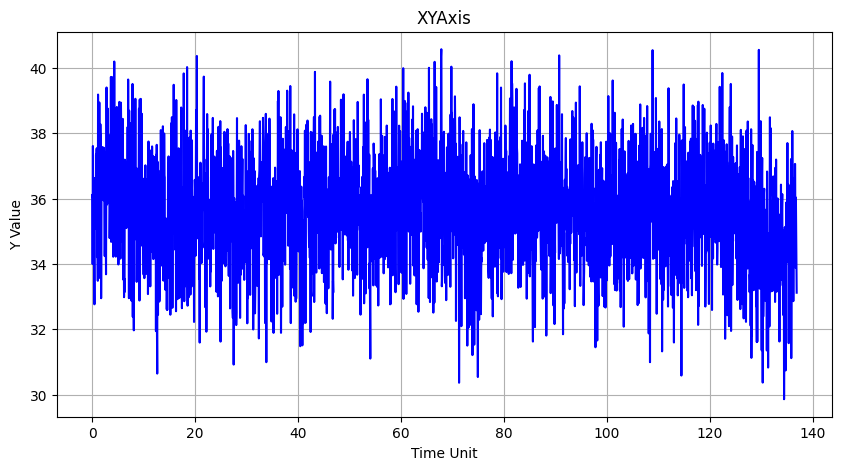

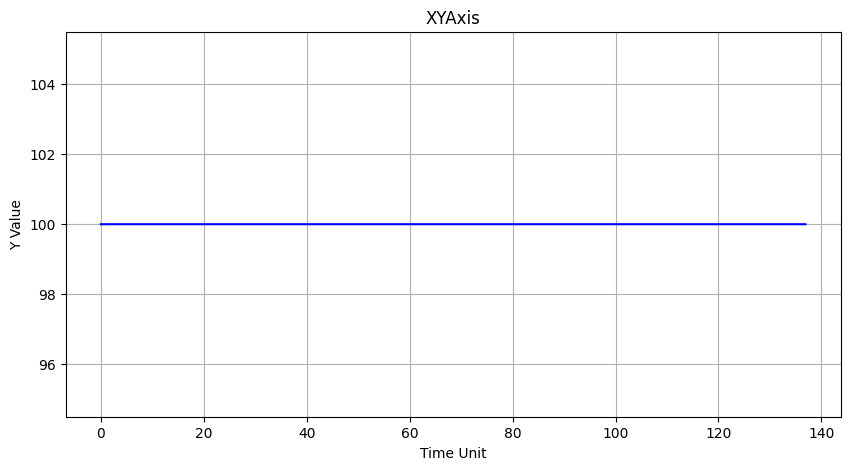

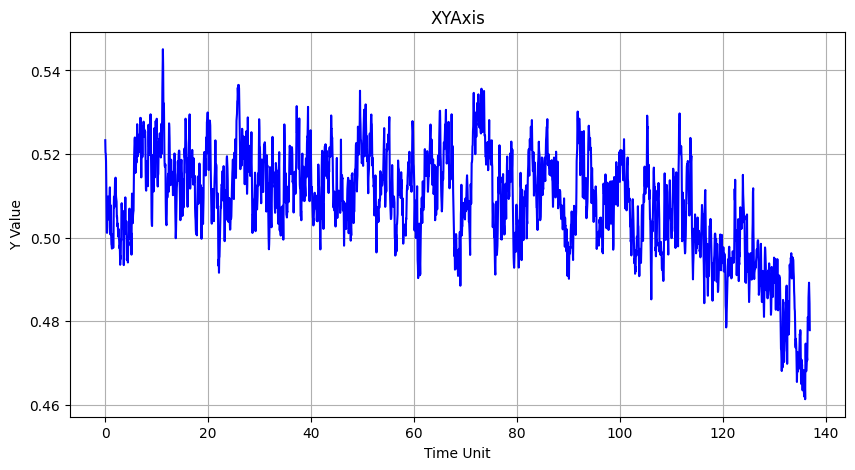

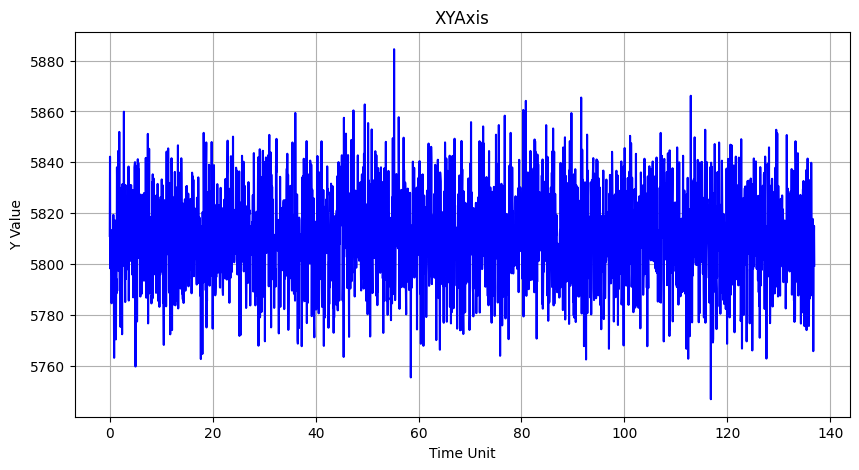

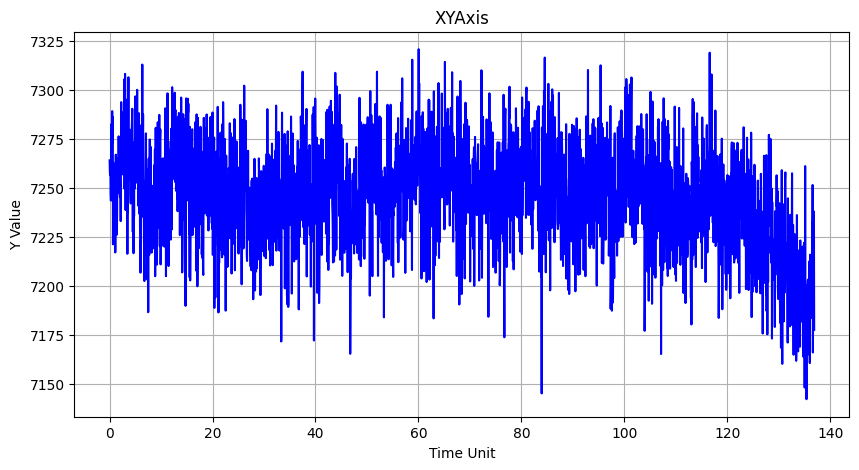

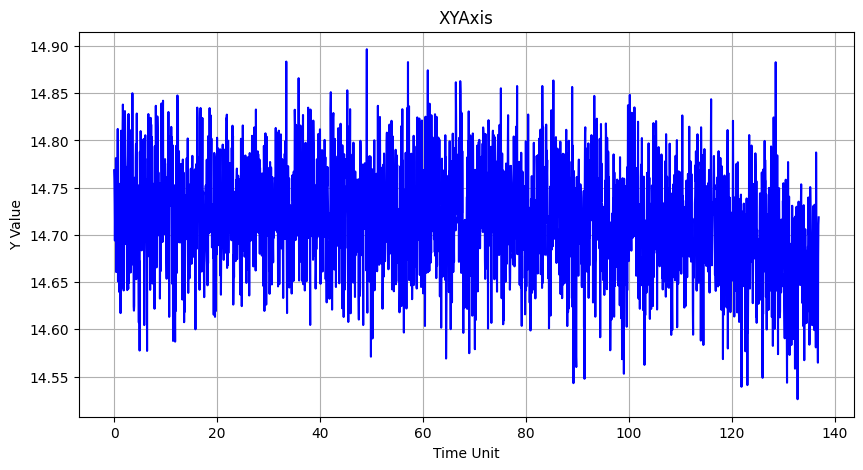

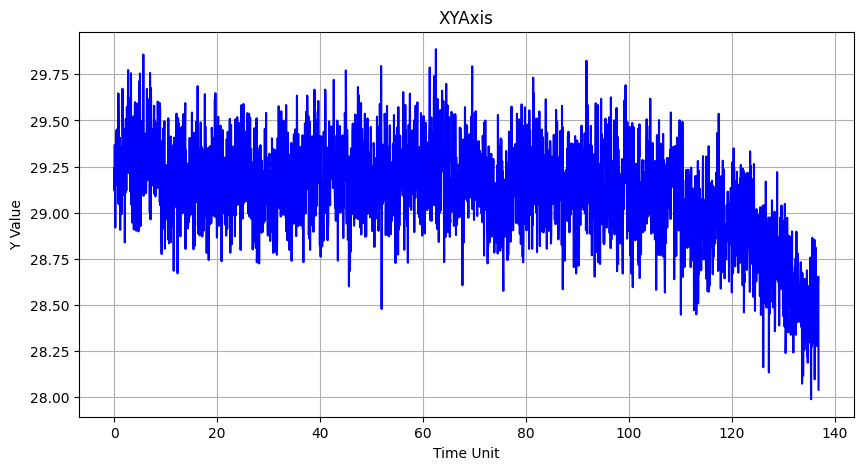

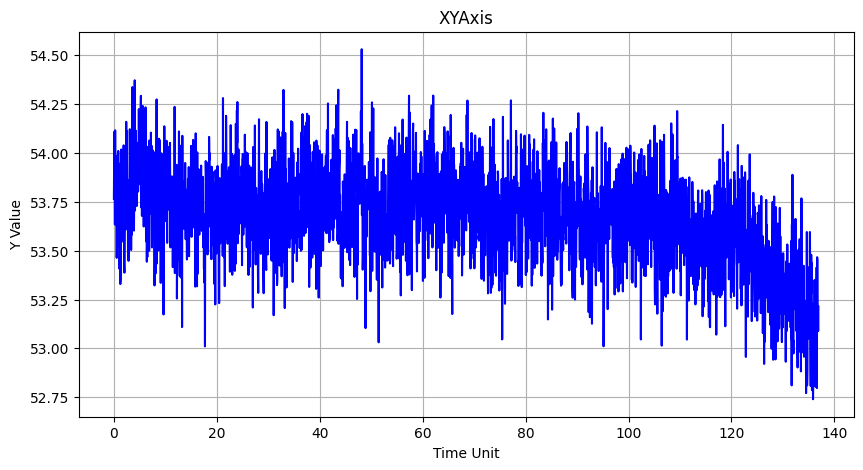

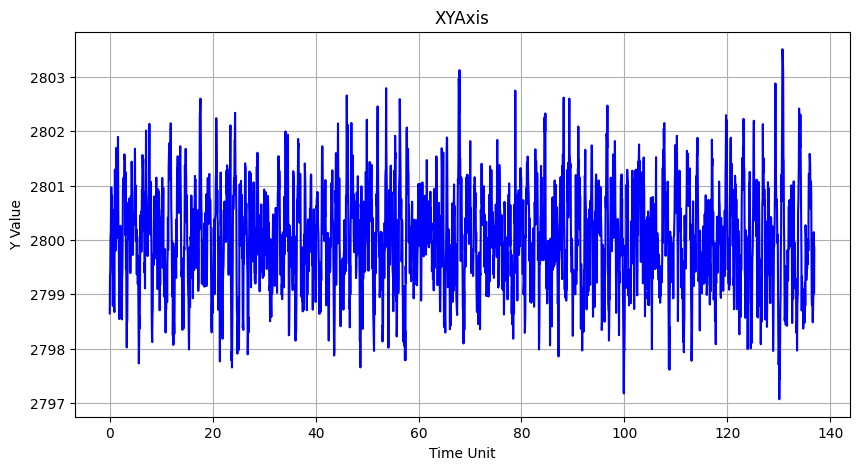

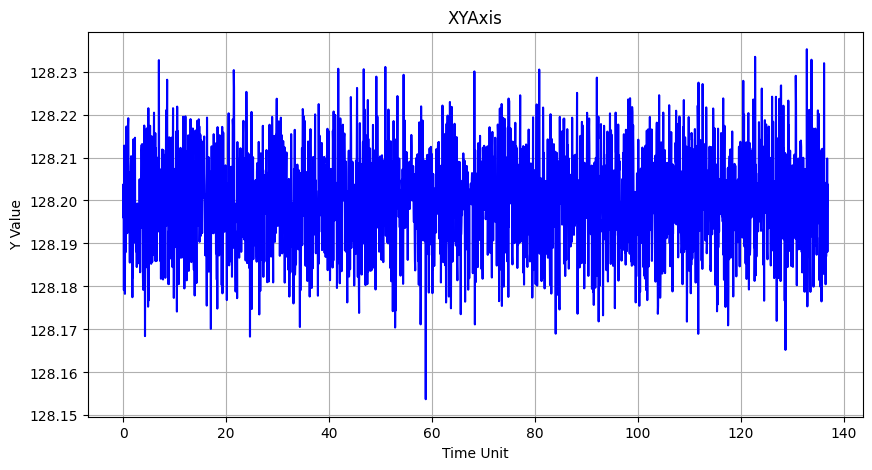

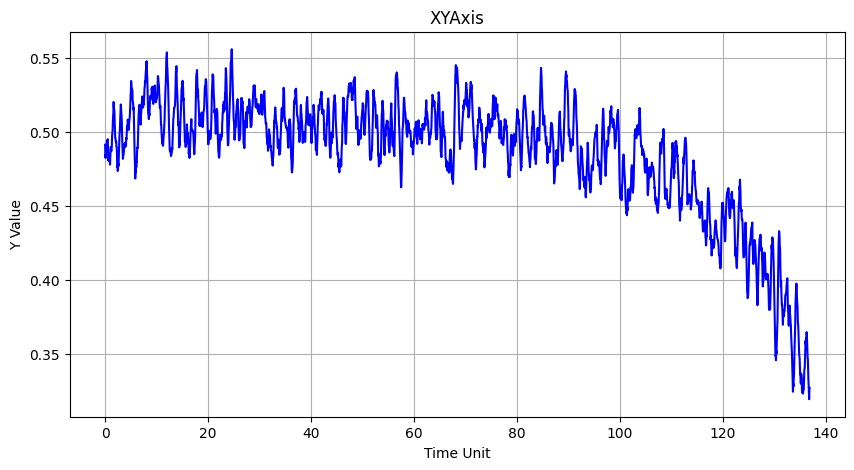

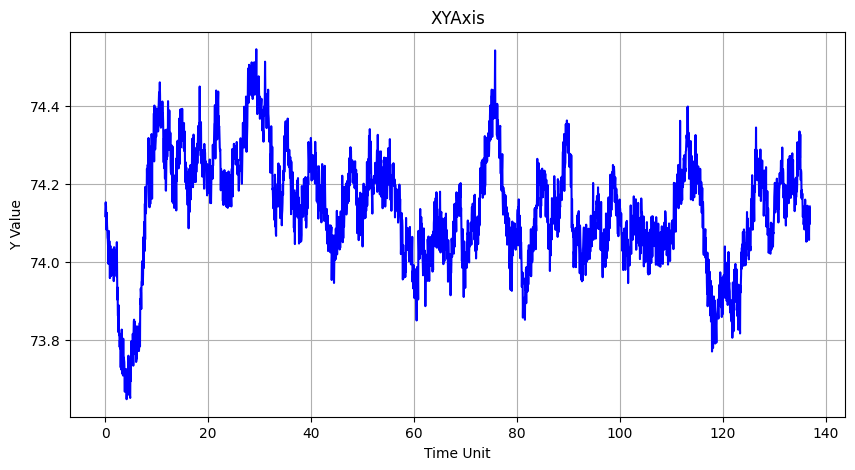

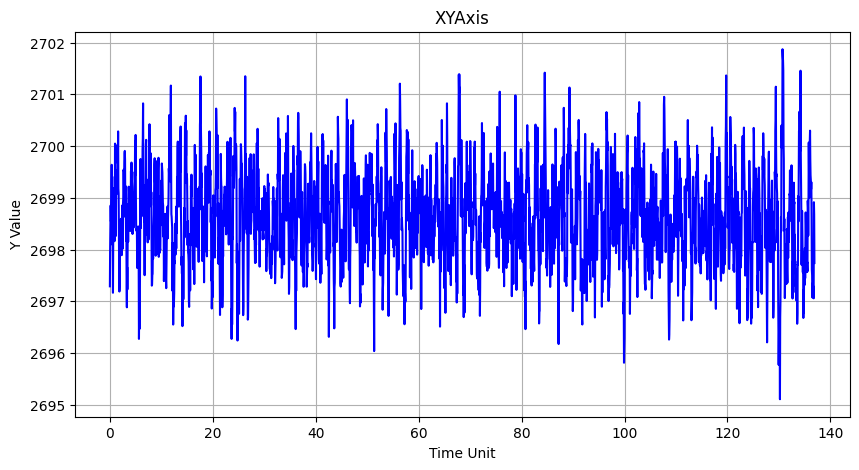

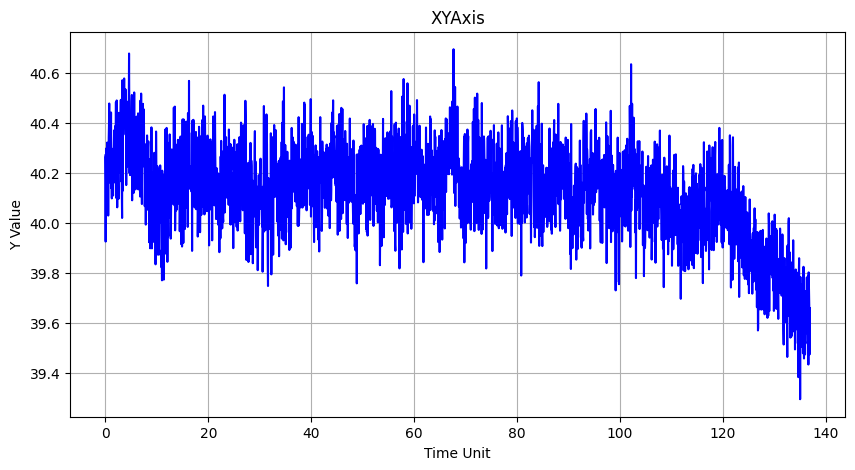

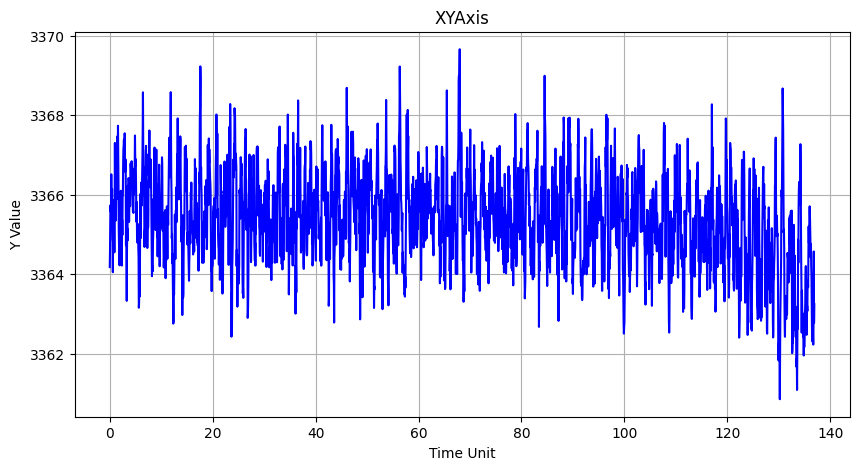

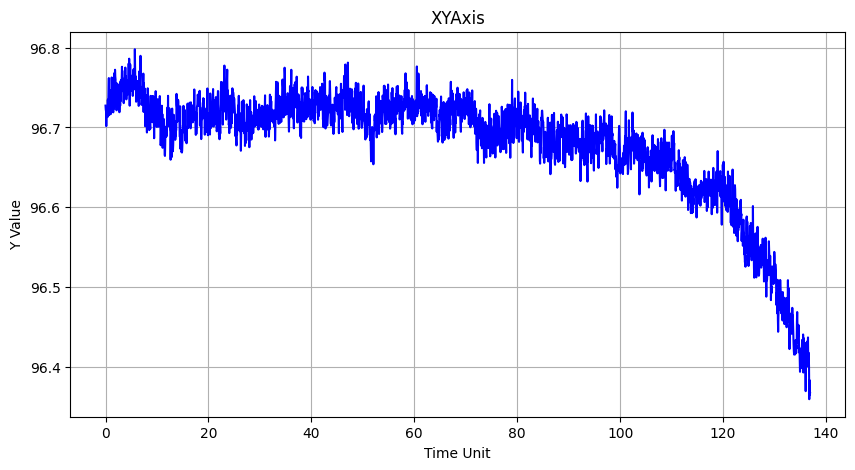

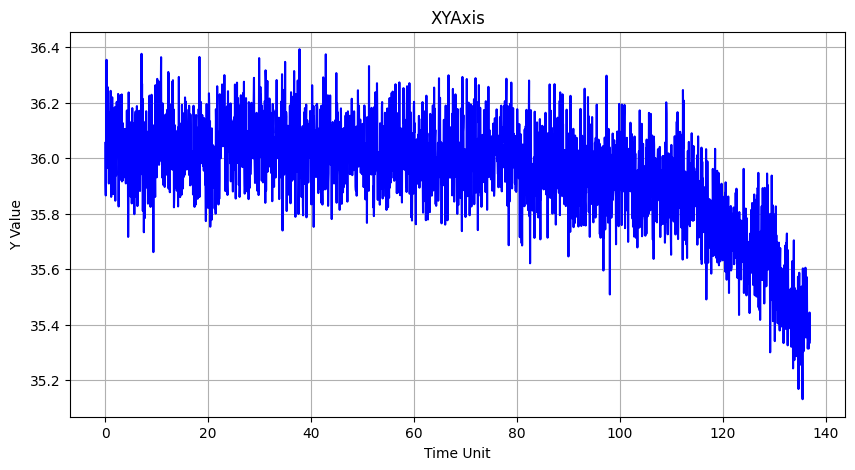

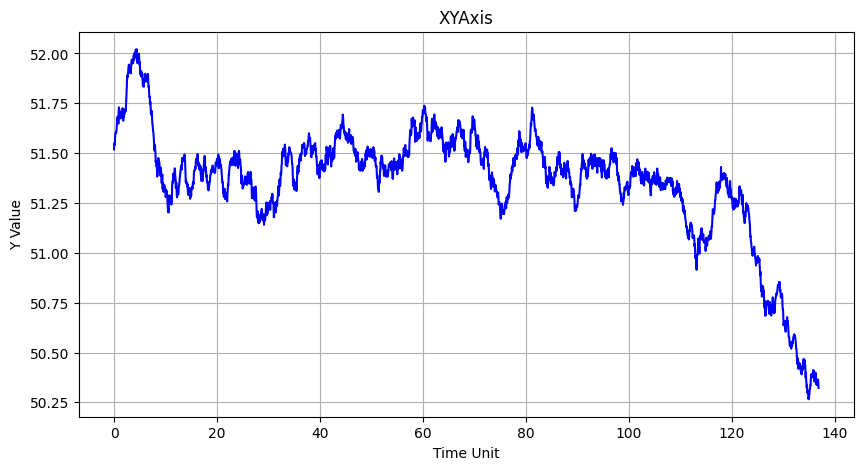

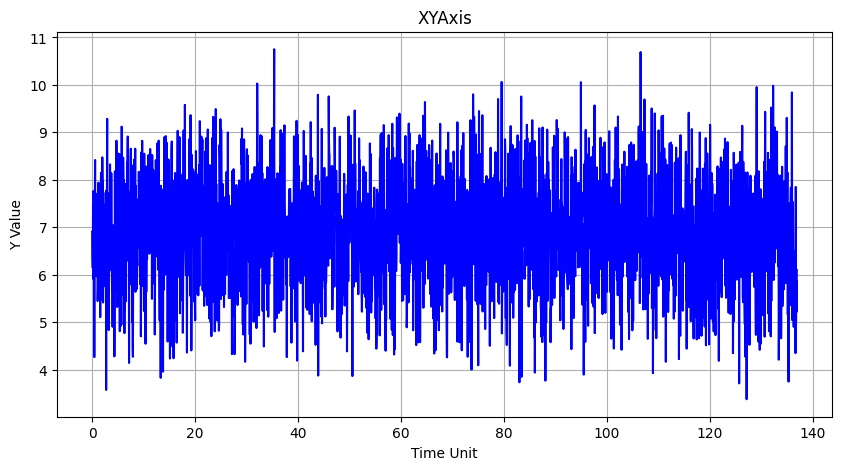

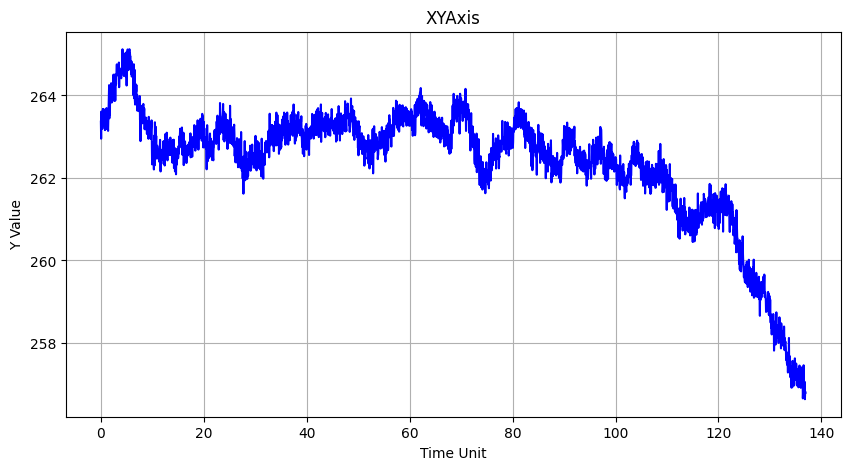

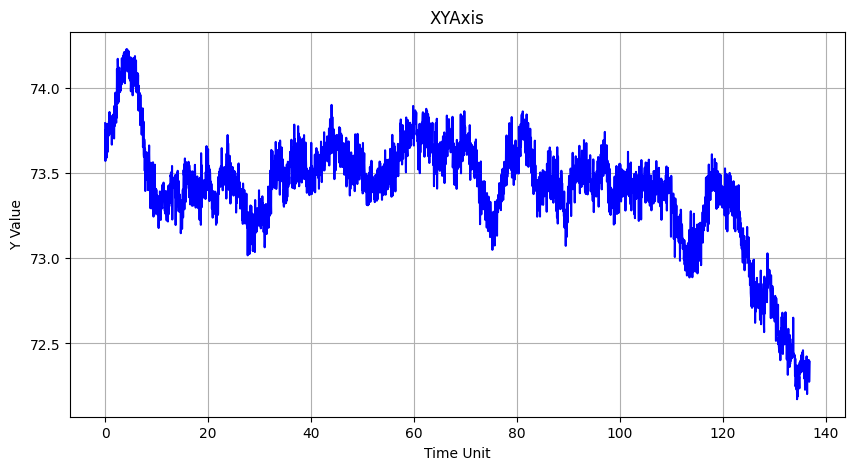

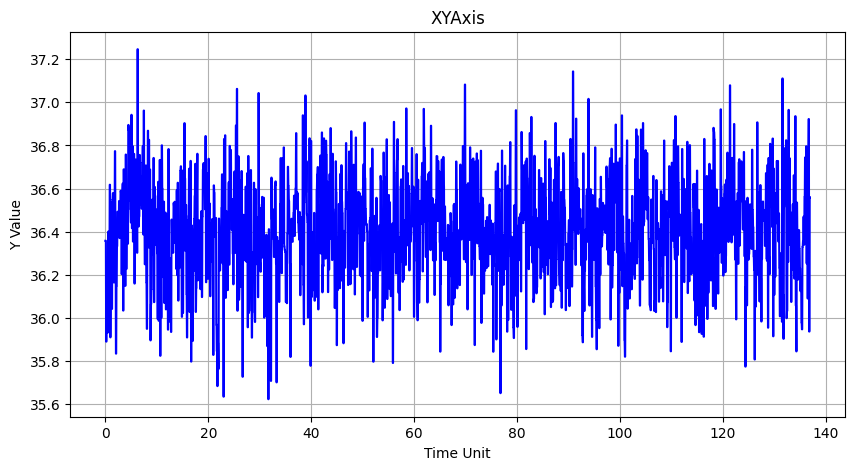

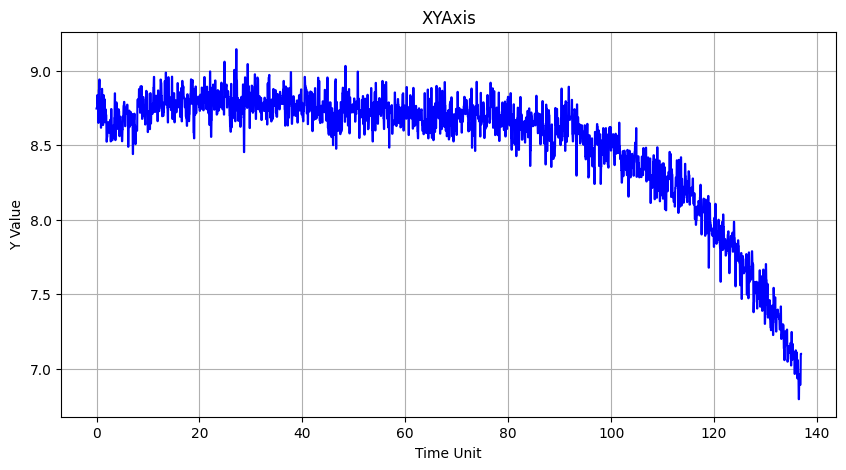

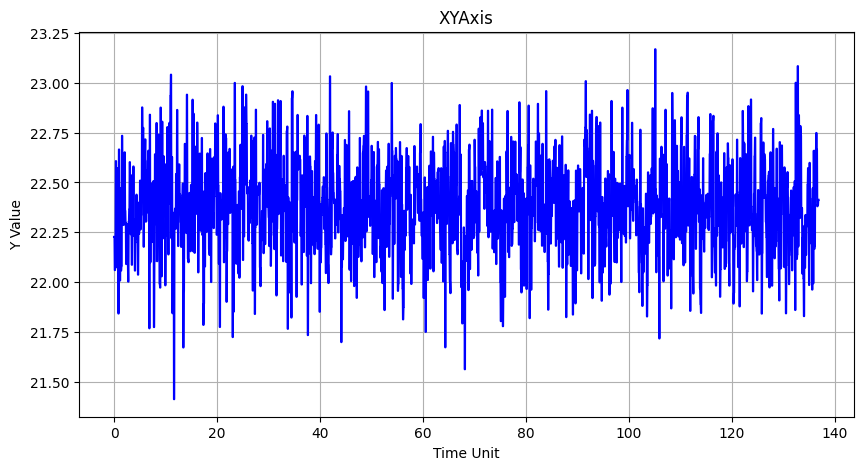

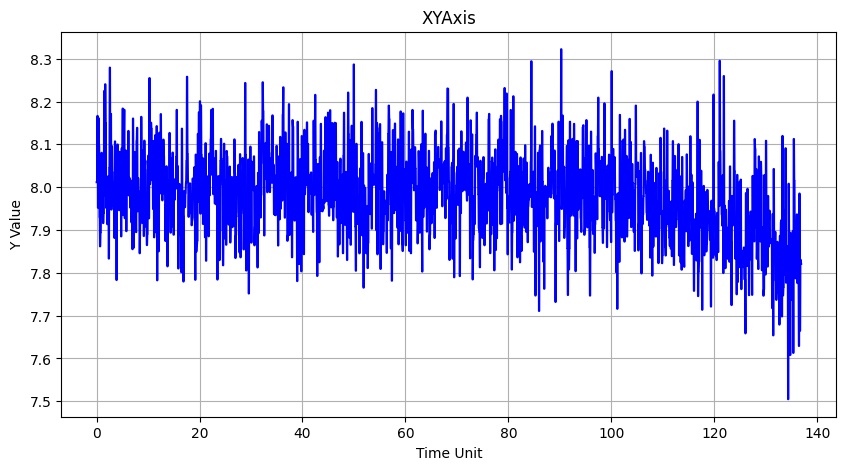

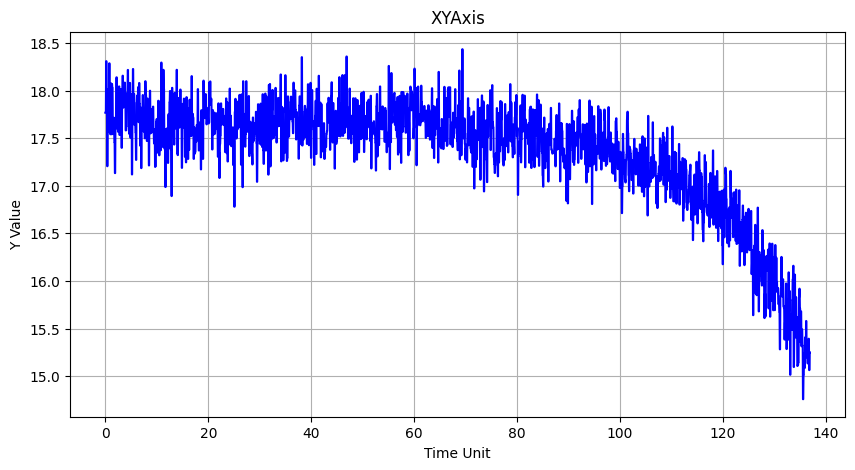

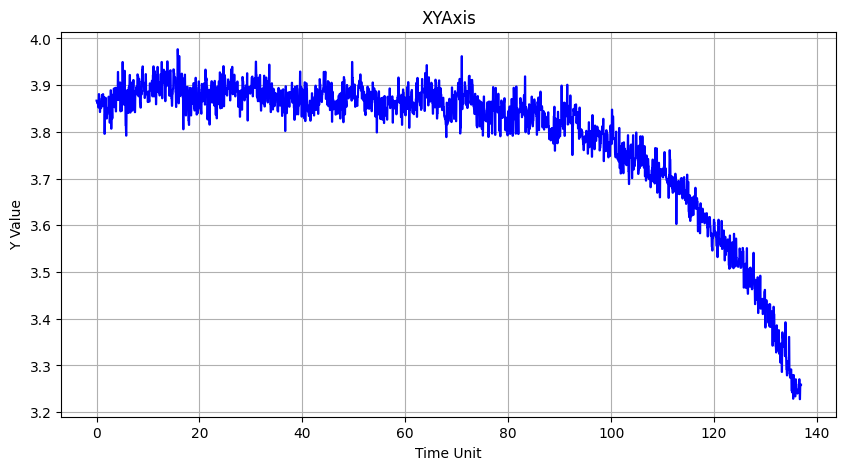

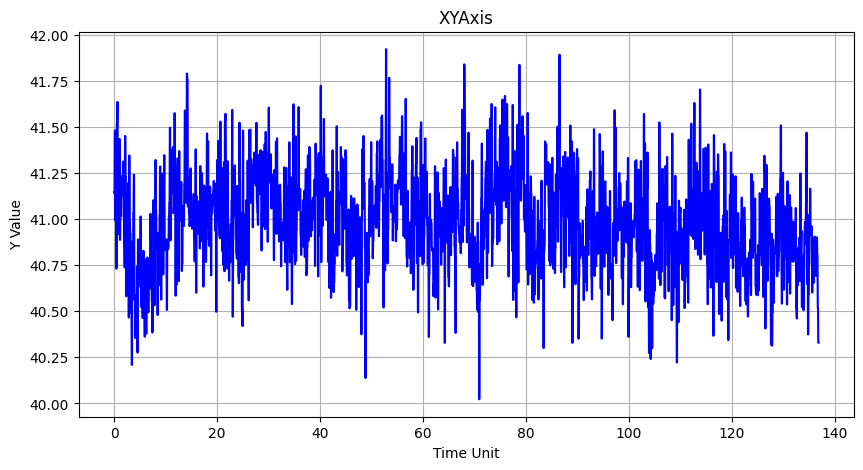

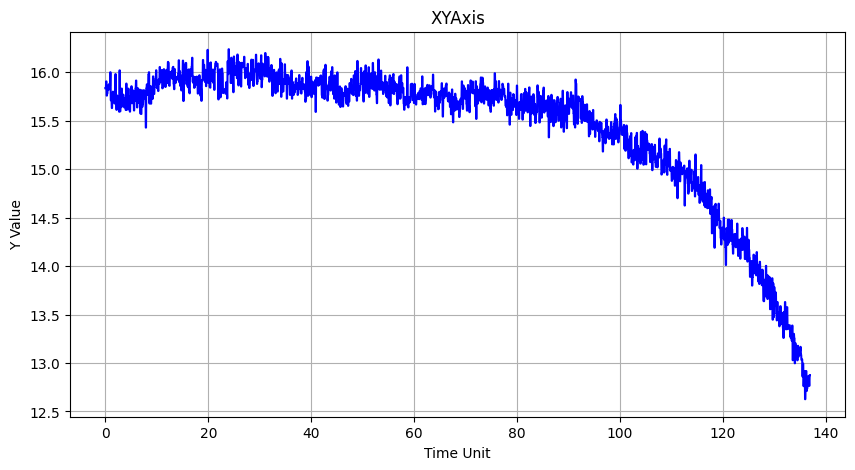

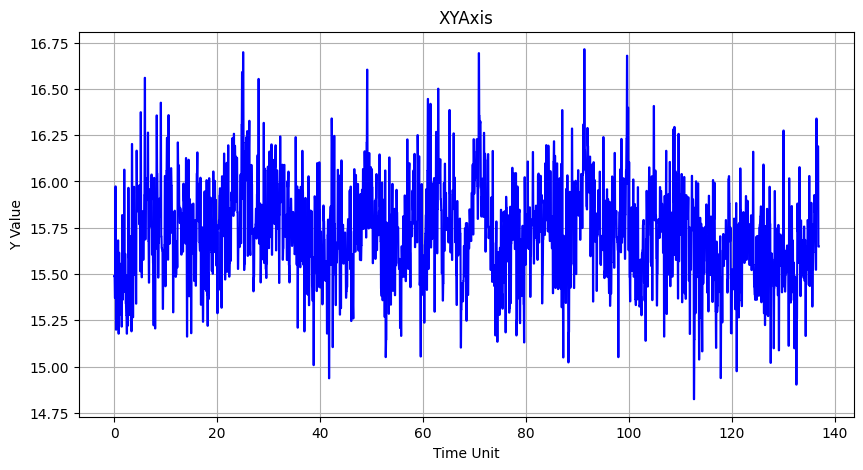

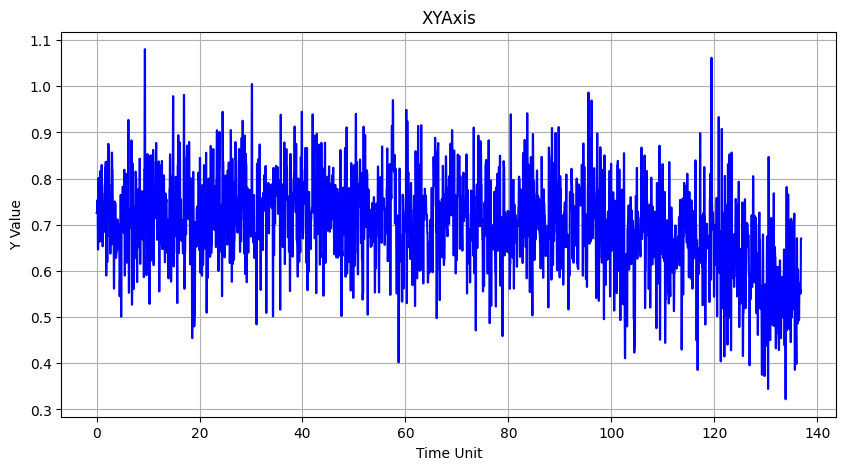

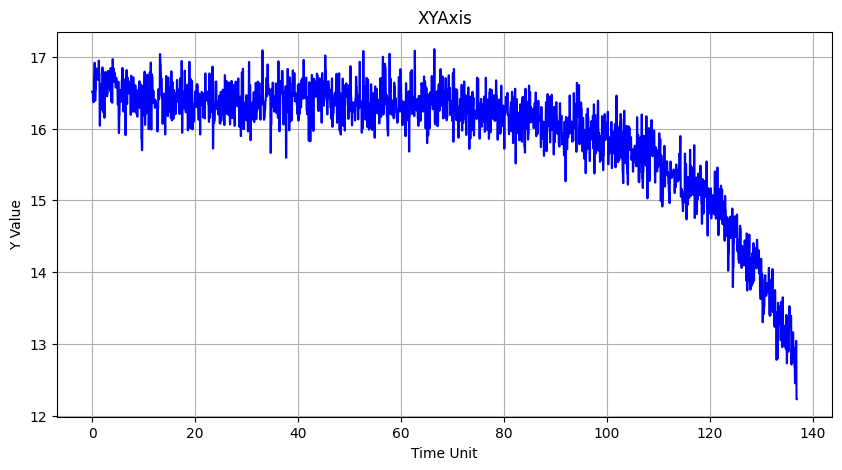

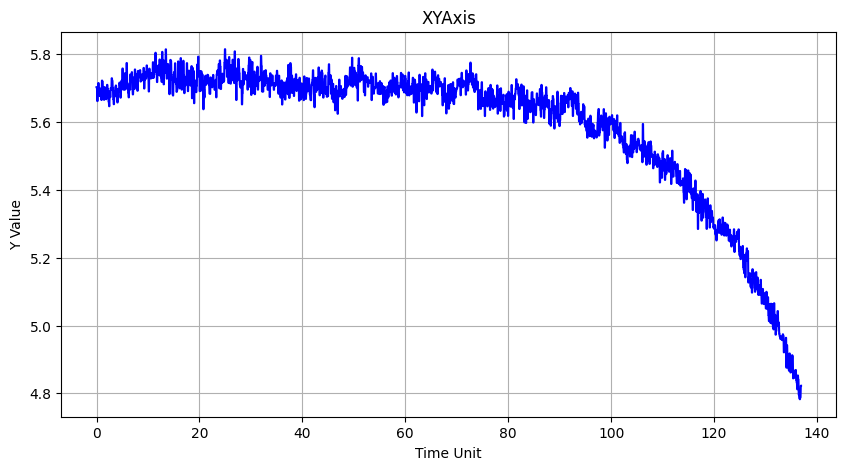

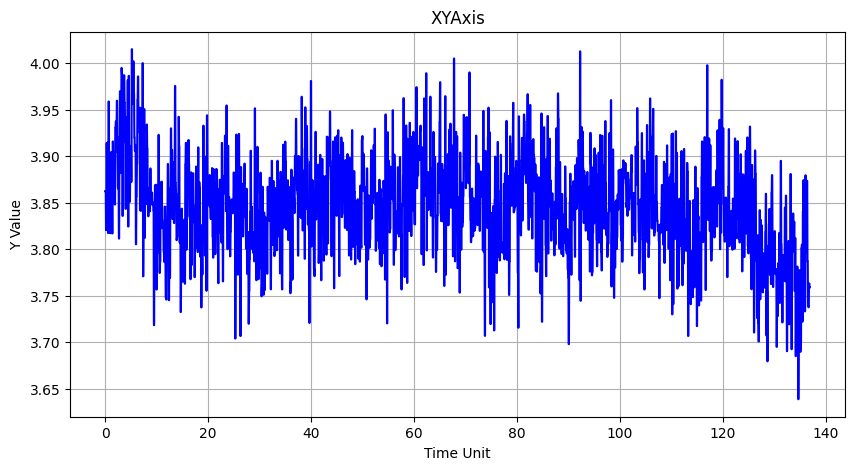

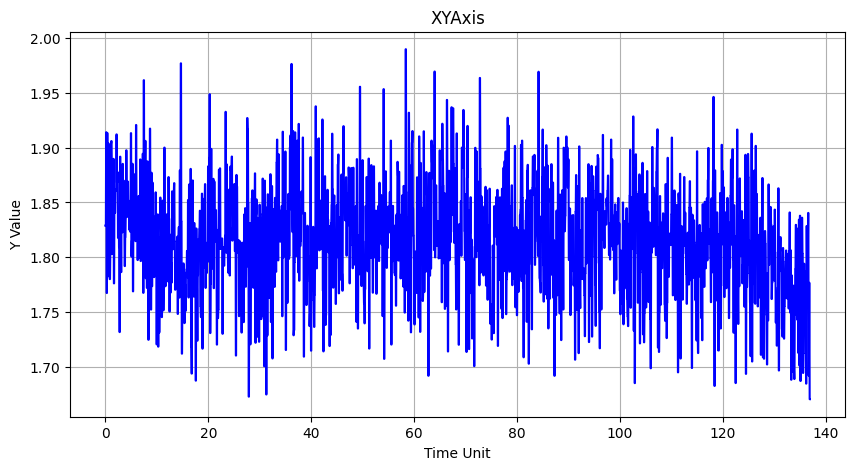

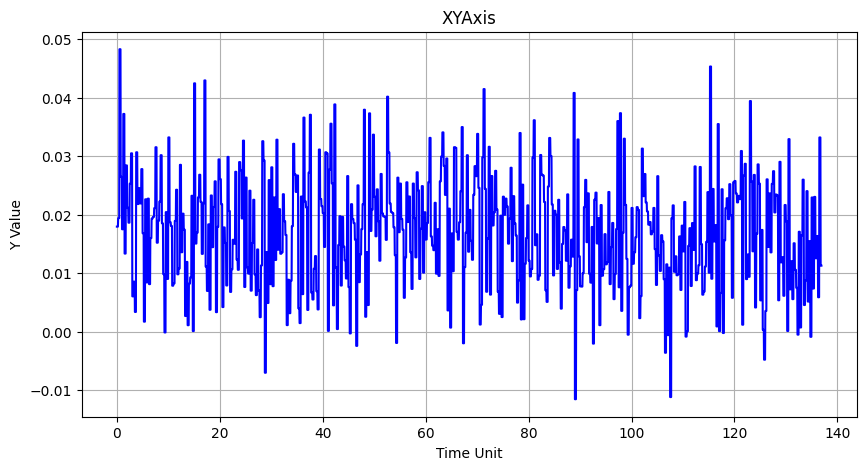

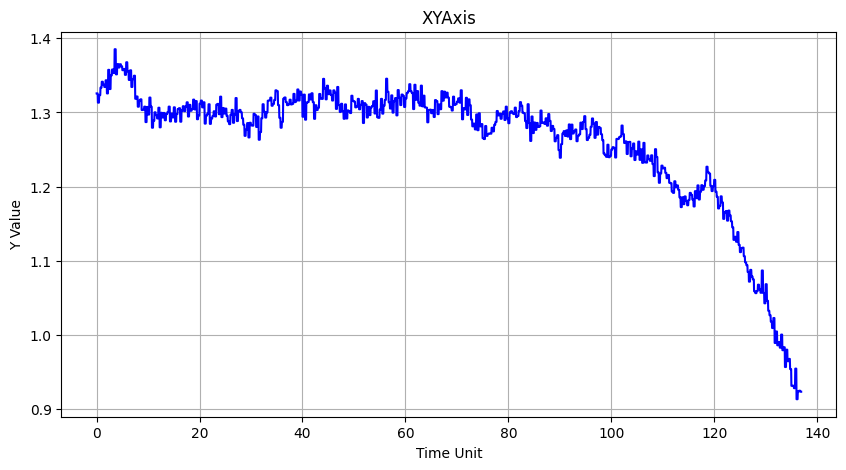

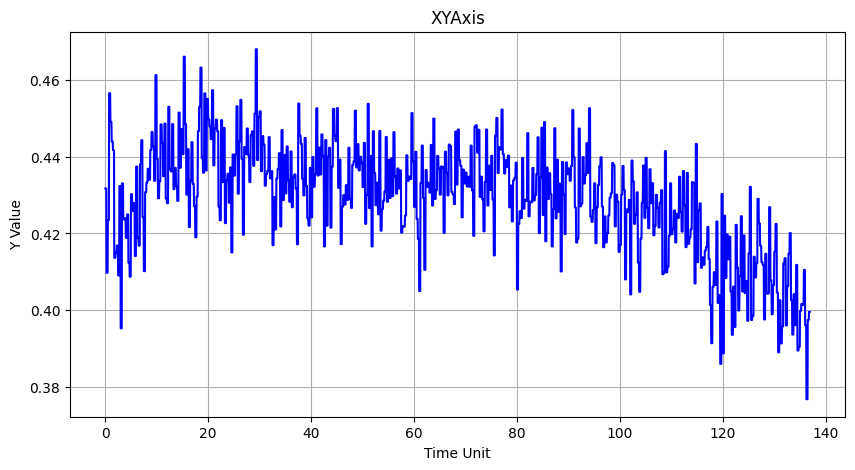

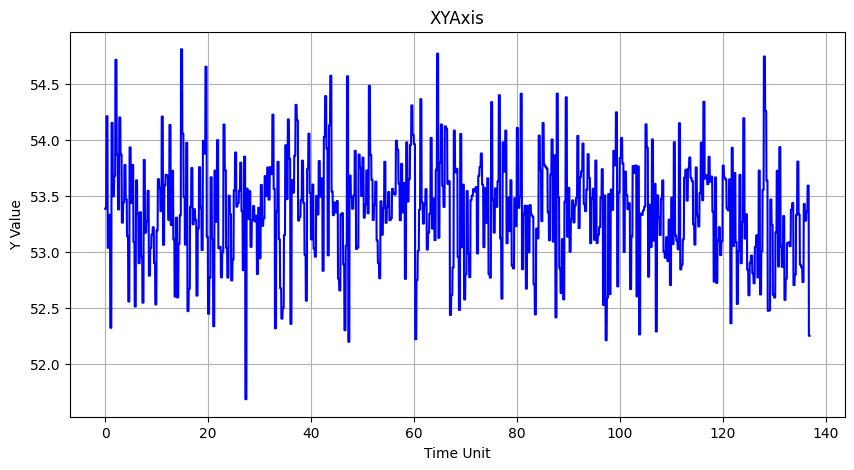

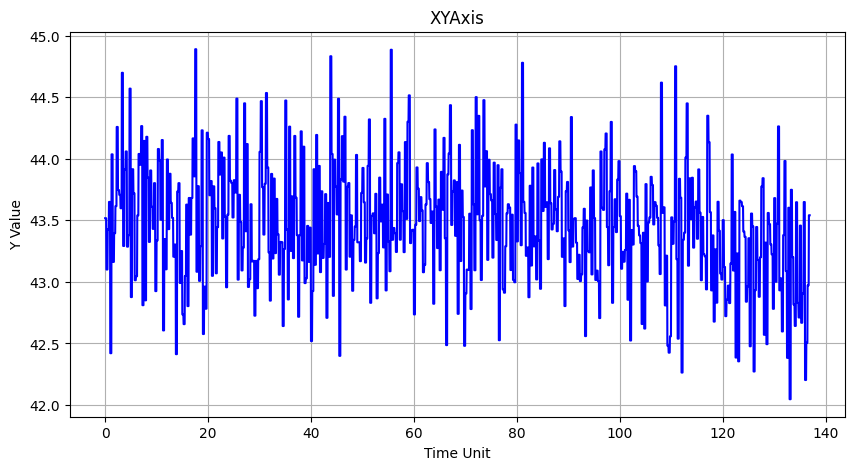

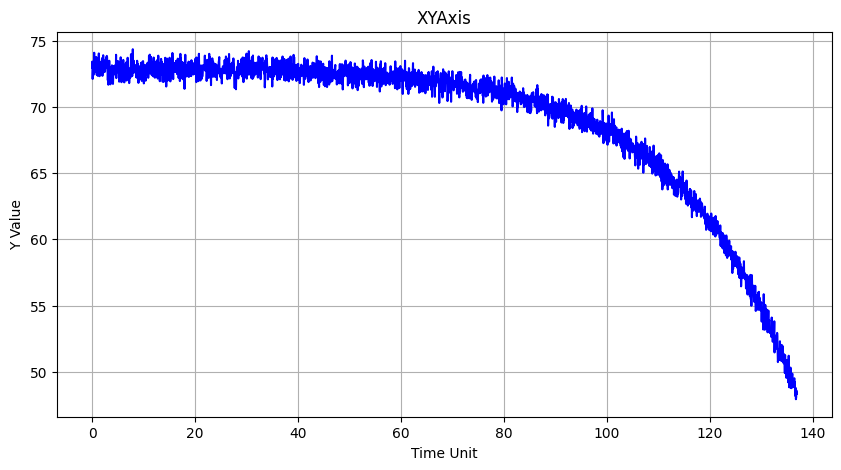

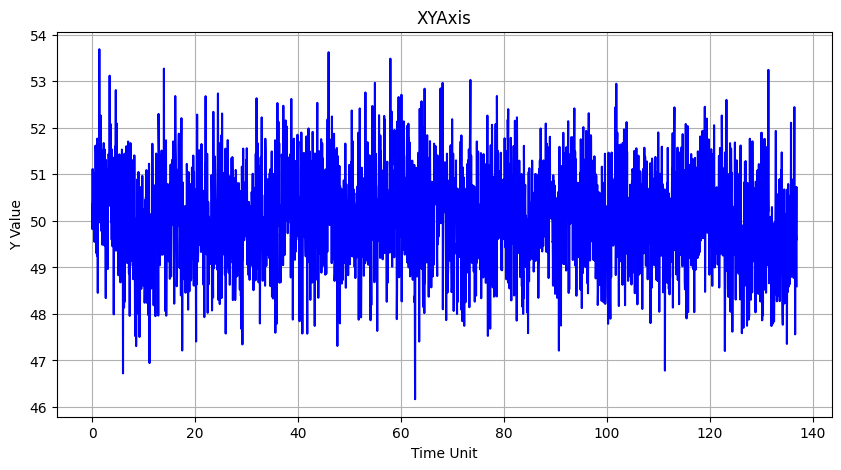

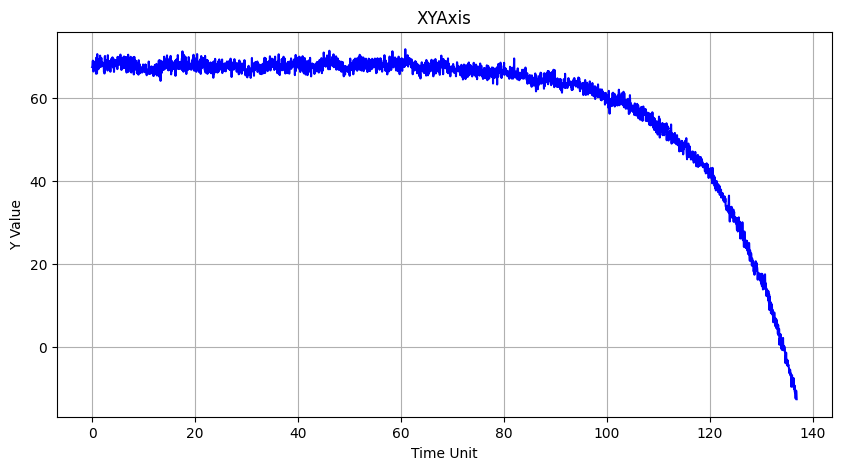

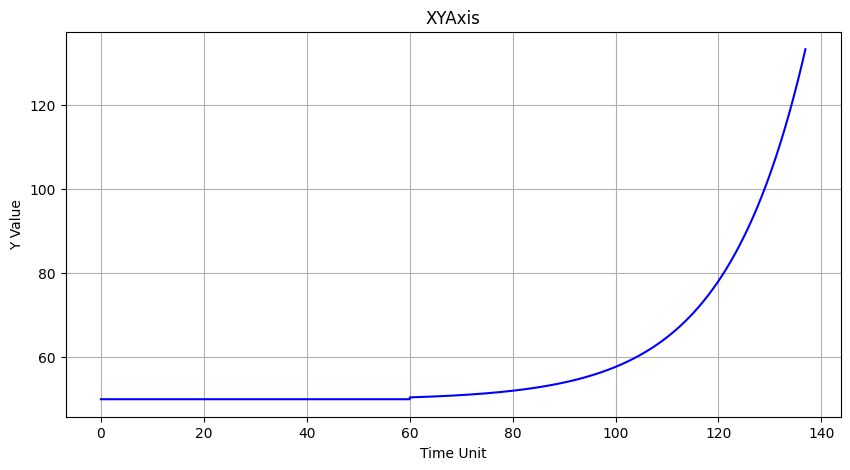

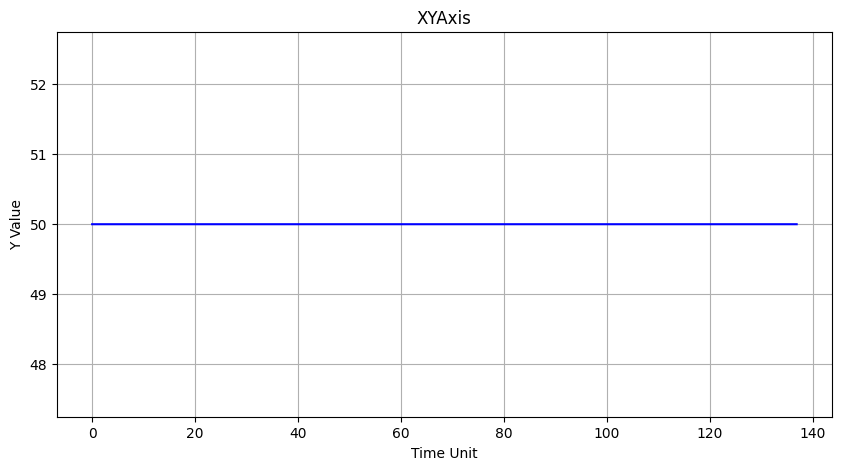

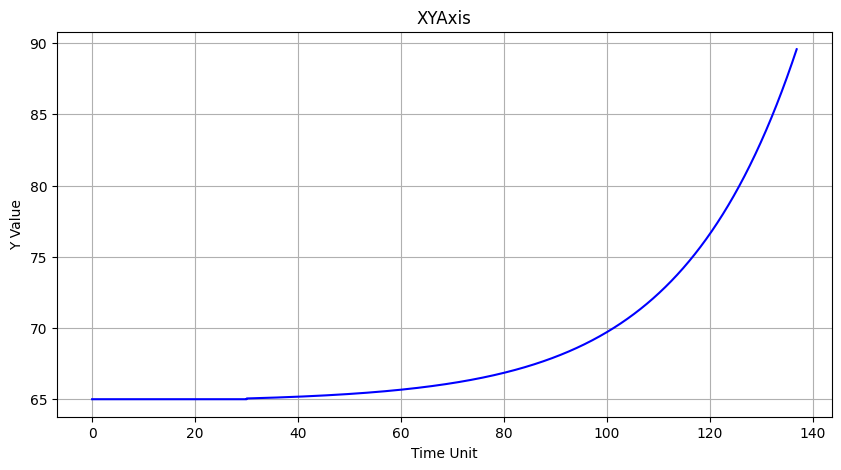

In [4]:
# Draw the data
curTrajectory = preData.getTrajectoryAt(inData= cleanData, case = 2, idxTrajectory= 1)
for feature in preData.allHeadline:
    plot.draw2D(curTrajectory["Time"],curTrajectory[feature])

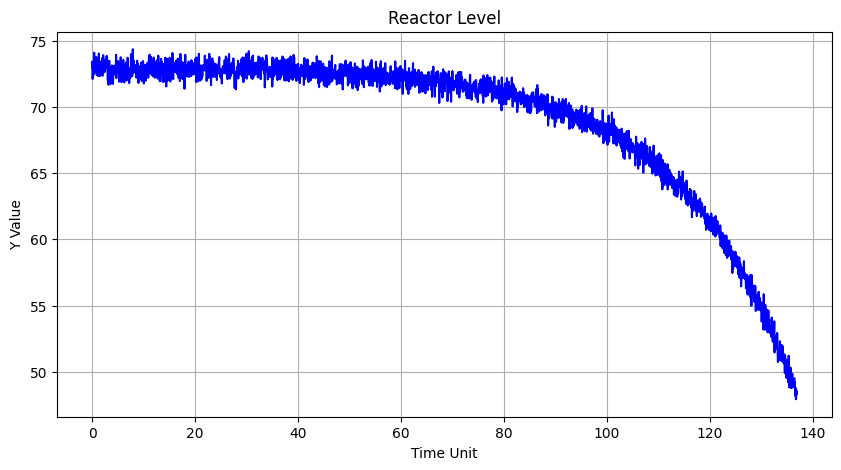

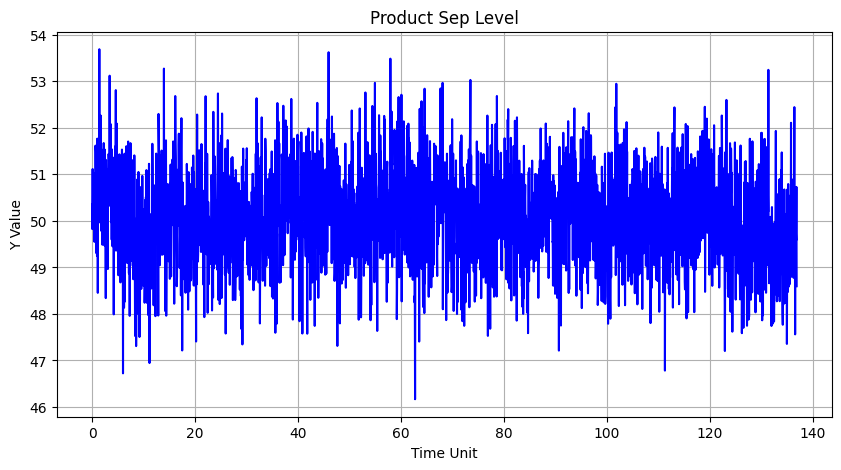

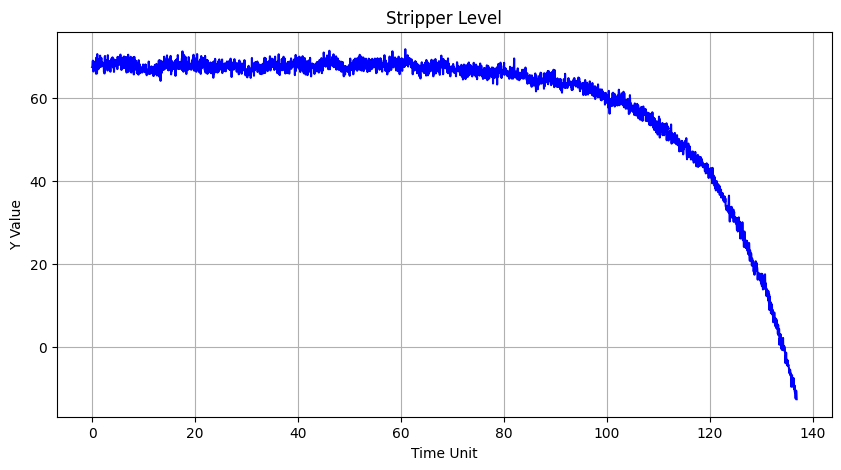

In [3]:
for idx in range(1):
    curTrajectory = preData.getTrajectoryAt(inData= rawData, case = 2, idxTrajectory= idx + 1)
    for idxHeadline in ['Reactor Level', 'Product Sep Level', 'Stripper Level']: 
        plot.draw2D(curTrajectory["Time"],curTrajectory[idxHeadline], title=idxHeadline)


In [7]:
cleanData           = preData.cleanData(rawSignal               =   withoutInitRawData,
                                            columnName          =   preData.allWithoutLabel,
                                            getMovingAverage    =   True,
                                            flipToDown          =   True)
# ---------------------------
# For label, flip only
cleanData           = preData.cleanData(rawSignal           =   cleanData,
                                        columnName          =   preData.degraLiq,
                                        getMovingAverage    =   False,
                                        flipToDown          =   True)

movedData           = preData.movingToPeak(cleanData)


NameError: name 'withoutInitRawData' is not defined

In [ ]:
# Draw the data
curTrajectory = preData.getTrajectoryAt(inData= cleanData, case = 2, idxTrajectory= 1)
for feature in preData.allHeadline:
    plot.draw2D(curTrajectory["Time"],curTrajectory[feature],title=feature)

In [ ]:
# Draw the data
print(cleanData)

### d. Normalize the data

In [ ]:
norData             = preData.normalizeDataAllModes(movedData)                # Normalize the data
# print(norData)

In [ ]:
# Draw the data
curTrajectory = preData.getTrajectoryAt(inData = norData, case = 2, idxTrajectory = 1)
for feature in preData.allHeadline:
    print(feature)
    plot.draw2D(curTrajectory["Time"],curTrajectory[feature],title=feature)

In [ ]:
plot = MatPlot()

plot.subPlotMultiImg(inY = hi["reactor"],  numRow=20, numCol=5)

### g. Split into each sequence

In [ ]:

seqTrainXY   = preData.getTensorData(norData, component =   "reactor", case = 1 )
# seqValXY   = preData.splitAllDataIntoSequences(valXY)  

# print(seqTrainXY[0].shape,seqTrainXY[1].shape)
# print(seqTrainXY[0][2011][:,0])

### h. Visualize the tensor data

In [ ]:

# Creating an array from 1 to 3000
#time = np.arange(1, 10)
# t= 0:200
# plot.draw1D(yCoor=seqTrainXY[1][0:t])
plot.draw1D(yCoor=seqTrainXY[0][2011][:,3])
            


# 4. Model and training

### To tensor

In [ ]:
tensorTrainXY       = data.TensorDataset(seqTrainXY[0],seqTrainXY[1])
tensorValXY         = data.TensorDataset(seqValXY[0],seqValXY[1])

In [ ]:
train_loader = data.DataLoader(tensorTrainXY,
                                batch_size  =   config.batch_size,
                                shuffle     =   False, 
                                num_workers =   config.num_workers)
        
val_loader = data.DataLoader(  tensorValXY, 
                                batch_size  =   config.val_batch_size, 
                                shuffle     =   False, 
                                num_workers =   config.num_workers)